# Laboratorio 3 — Modelo Clásico
## Random Forest

En este notebook se entrena un **Random Forest** sobre las imágenes aplanadas del dataset ASL, como el algoritmo alternativo a las redes neuronales que pide el ejercicio 6. Se prueban las combinaciones de `n_estimators` y `max_depth` acordadas en `docs/report/03_seleccion_modelos.md`, se selecciona la mejor por accuracy en validación, y se evalúa esa configuración sobre el conjunto de prueba con las mismas métricas que se usaron para los tres modelos de `02_modelos_cnn.ipynb` (accuracy, precision y recall macro, y matriz de confusión), para que la comparación final en `05_comparacion_final.ipynb` sea directa.

## Setup y verificaciones

### Imports

In [1]:
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

SEED = 42
np.random.seed(SEED)


### Definicion de rutas

In [2]:
PROCESSED_DIR = Path("../data/processed")
RESULTS_DIR = Path("../results")

RESULTS_DIR.mkdir(parents=True, exist_ok=True)


### Carga de datos

In [3]:
X_train = np.load(PROCESSED_DIR / "X_train.npy")
y_train = np.load(PROCESSED_DIR / "y_train.npy")

X_val = np.load(PROCESSED_DIR / "X_val.npy")
y_val = np.load(PROCESSED_DIR / "y_val.npy")

X_test = np.load(PROCESSED_DIR / "X_test.npy")
y_test = np.load(PROCESSED_DIR / "y_test.npy")

classes = pd.read_csv(PROCESSED_DIR / "classes.csv")["label"].tolist()

print("Datos cargados correctamente.")


Datos cargados correctamente.


### Aplanado de imágenes

Random Forest no trabaja sobre tensores 4D como las CNN: cada imagen de 64×64×3 se aplana a un vector de 12,288 posiciones. Es la misma representación de entrada que usa la red Fully Connected en `02_modelos_cnn.ipynb`, lo que hace la comparación entre ambos modelos más directa (mismo input, distinto algoritmo).

In [4]:
X_train_flat = X_train.reshape(len(X_train), -1)
X_val_flat = X_val.reshape(len(X_val), -1)
X_test_flat = X_test.reshape(len(X_test), -1)

print("Shape de X_train aplanado:", X_train_flat.shape)


Shape de X_train aplanado: (14210, 12288)


## Búsqueda de hiperparámetros

Se prueban las combinaciones de `n_estimators` en {100, 300} y `max_depth` en {None, 20, 40} acordadas en el plan de selección de modelos (6 combinaciones en total). Cada combinación se entrena sobre train y se evalúa por accuracy sobre validación, siguiendo el mismo criterio de selección que se usó para las CNN y la red Fully Connected.

In [5]:
n_estimators_grid = [100, 300]
max_depth_grid = [None, 20, 40]

resultados_busqueda = []

for n_estimators in n_estimators_grid:
    for max_depth in max_depth_grid:
        inicio = time.time()

        rf = RandomForestClassifier(
            n_estimators=n_estimators,
            max_depth=max_depth,
            random_state=SEED,
            n_jobs=-1
        )
        rf.fit(X_train_flat, y_train)

        val_pred = rf.predict(X_val_flat)
        val_accuracy = accuracy_score(y_val, val_pred)

        duracion = time.time() - inicio

        resultados_busqueda.append({
            "n_estimators": n_estimators,
            "max_depth": max_depth if max_depth is not None else "None",
            "val_accuracy": val_accuracy,
            "tiempo_s": duracion,
            "modelo": rf
        })

        print(
            f"n_estimators={n_estimators}, max_depth={max_depth} "
            f"-> val_accuracy={val_accuracy:.4f} ({duracion:.1f}s)"
        )


n_estimators=100, max_depth=None -> val_accuracy=0.9675 (11.6s)
n_estimators=100, max_depth=20 -> val_accuracy=0.9649 (12.8s)
n_estimators=100, max_depth=40 -> val_accuracy=0.9675 (10.4s)
n_estimators=300, max_depth=None -> val_accuracy=0.9708 (32.7s)
n_estimators=300, max_depth=20 -> val_accuracy=0.9685 (34.8s)
n_estimators=300, max_depth=40 -> val_accuracy=0.9708 (33.5s)


### Tabla comparativa de combinaciones

In [6]:
busqueda_df = pd.DataFrame([
    {k: v for k, v in r.items() if k != "modelo"}
    for r in resultados_busqueda
]).sort_values("val_accuracy", ascending=False).reset_index(drop=True)

busqueda_df


,n_estimators,max_depth,val_accuracy,tiempo_s
0,300,None,0.970772,32.732092
1,300,40,0.970772,33.535213
2,300,20,0.968473,34.808883
3,100,None,0.967488,11.636261
4,100,40,0.967488,10.397970
5,100,20,0.964860,12.797316


### Selección del mejor modelo

In [7]:
mejor_resultado = max(resultados_busqueda, key=lambda r: r["val_accuracy"])
mejor_rf = mejor_resultado["modelo"]
mejor_config_nombre = (
    f"Random Forest (n_estimators={mejor_resultado['n_estimators']}, "
    f"max_depth={mejor_resultado['max_depth']})"
)

print(
    f"Mejor combinación: n_estimators={mejor_resultado['n_estimators']}, "
    f"max_depth={mejor_resultado['max_depth']} "
    f"(val_accuracy={mejor_resultado['val_accuracy']:.4f})"
)


Mejor combinación: n_estimators=300, max_depth=None (val_accuracy=0.9708)


## Evaluación sobre el conjunto de prueba

In [8]:
def evaluate_sklearn_model(model, X_test, y_test, model_name):
    y_pred = model.predict(X_test)

    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, average="macro", zero_division=0)
    recall = recall_score(y_test, y_pred, average="macro", zero_division=0)

    print(model_name)
    print(f"Accuracy:  {accuracy:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall:    {recall:.4f}")

    return {
        "Modelo": "Random Forest",
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall
    }, y_pred


In [9]:
rf_metrics, rf_pred = evaluate_sklearn_model(
    mejor_rf,
    X_test_flat,
    y_test,
    mejor_config_nombre
)


Random Forest (n_estimators=300, max_depth=None)
Accuracy:  0.9718
Precision: 0.9724
Recall:    0.9718


### Matriz de confusión

In [10]:
def plot_confusion_matrix(
    y_true,
    y_pred,
    class_names,
    title
):
    cm = confusion_matrix(
        y_true,
        y_pred
    )

    fig, ax = plt.subplots(
        figsize=(14, 14)
    )

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=class_names
    )

    disp.plot(
        ax=ax,
        cmap="Greens",
        xticks_rotation=90,
        colorbar=False
    )

    ax.set_title(title)

    plt.tight_layout()
    plt.show()


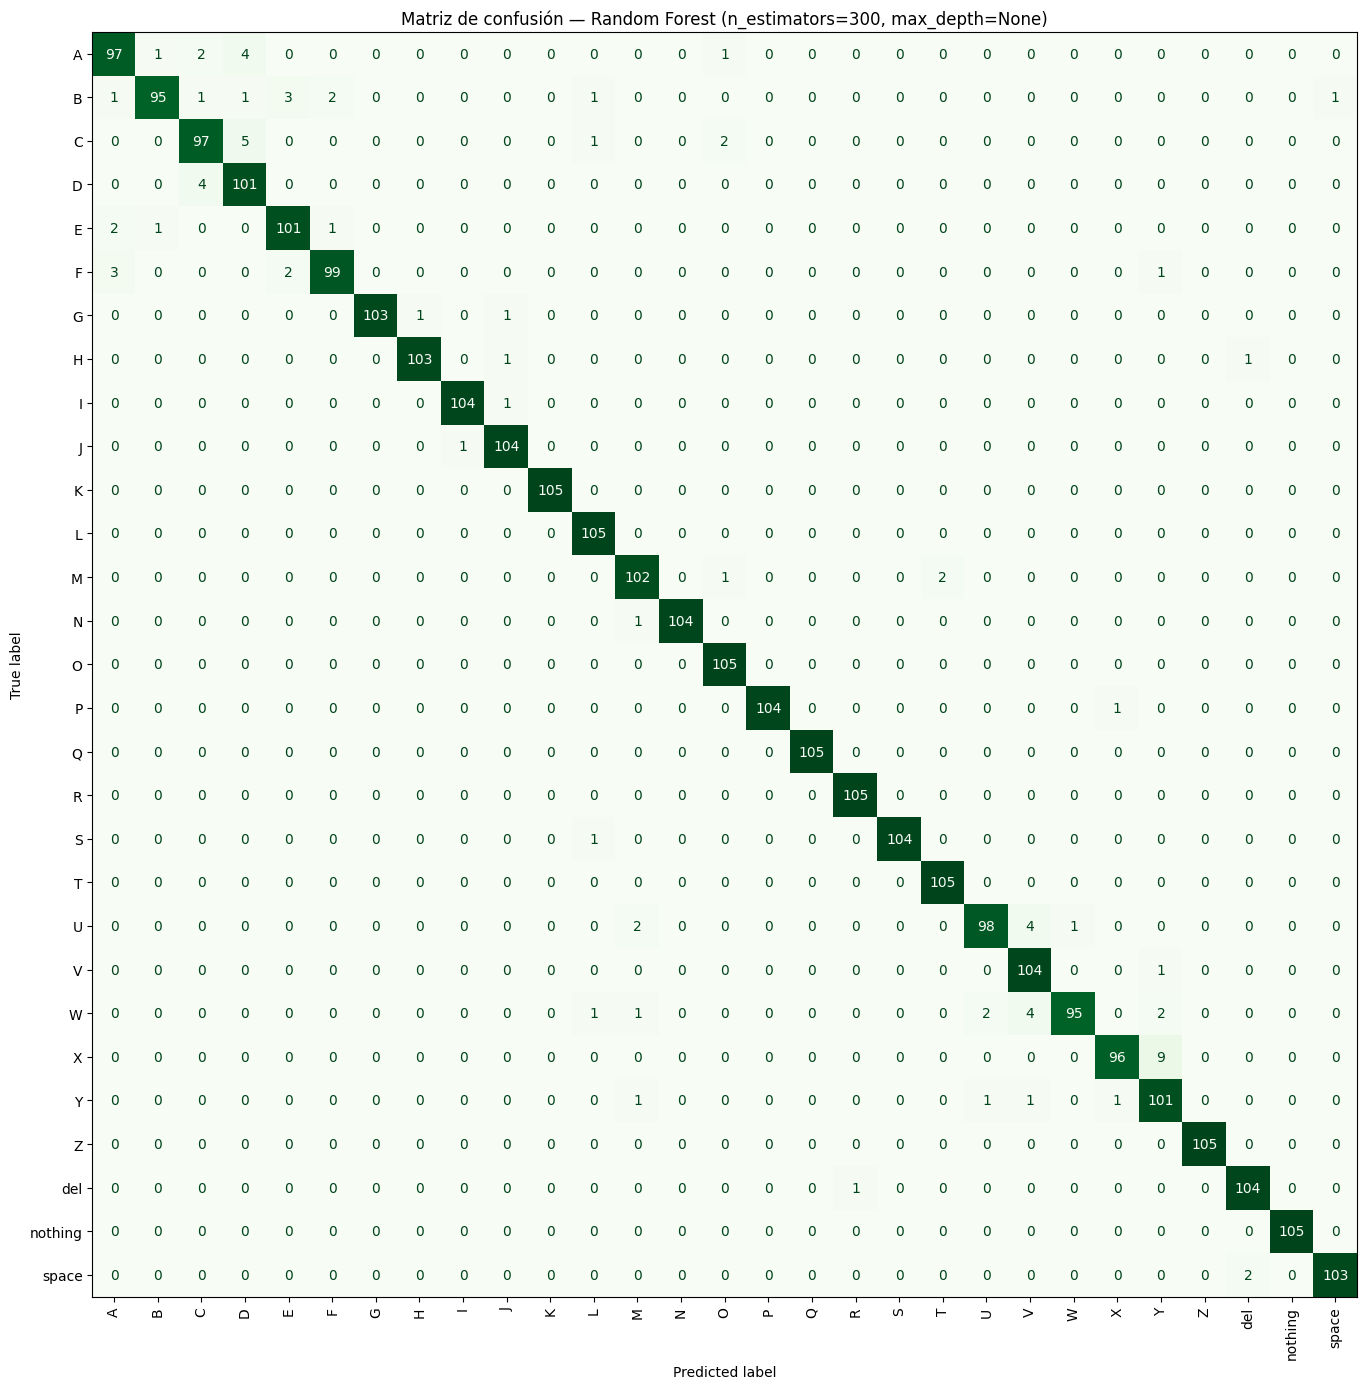

In [11]:
plot_confusion_matrix(
    y_test,
    rf_pred,
    classes,
    f"Matriz de confusión — {mejor_config_nombre}"
)


## Guardar métricas para la comparación final

Se guardan en `results/metrics_rf.csv` para que `05_comparacion_final.ipynb` las **cargue** en vez de volver a entrenar el Random Forest.

In [12]:
rf_metrics_df = pd.DataFrame([rf_metrics])
rf_metrics_path = RESULTS_DIR / "metrics_rf.csv"
rf_metrics_df.to_csv(rf_metrics_path, index=False)

print(f"Métricas guardadas en: {rf_metrics_path}")
rf_metrics_df


Métricas guardadas en: ../results/metrics_rf.csv


,Modelo,Accuracy,Precision,Recall
0,Random Forest,0.971757,0.972409,0.971757


## Conclusión

**Random Forest (n_estimators=300, max_depth=None)** fue la combinación con mejor accuracy de validación de las 6 evaluadas, y sobre el conjunto de prueba obtuvo un accuracy de **97.18%**, con precision macro de **97.24%** y recall macro de **97.18%**. Se eligió Random Forest como algoritmo alternativo a las redes neuronales porque es un modelo no paramétrico fácil de ajustar y de interpretar (importancia de variables, poca sensibilidad a la escala de los datos), y sirve como punto de comparación frente a un enfoque completamente distinto al de las CNN: en vez de aprender filtros convolucionales que detectan patrones espaciales locales, construye árboles de decisión directamente sobre la intensidad de cada píxel aplanado, sin ninguna noción de que un píxel está 'cerca' de otro. La comparación final contra CNN 1, CNN 2 y la red Fully Connected se hace en `notebooks/05_comparacion_final.ipynb`.
